In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Set a consistent aesthetic style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
np.random.seed(42)

In [2]:
epochs = np.arange(1, 21)
train_loss = 2.5 * np.exp(-0.2 * epochs) + np.random.normal(0, 0.03, size=len(epochs))
val_loss = 2.7 * np.exp(-0.18 * epochs) + 0.15 + np.random.normal(0, 0.04, size=len(epochs))
val_accuracy = 0.5 + 0.45 * (1 - np.exp(-0.15 * epochs)) + np.random.normal(0, 0.02, size=len(epochs))

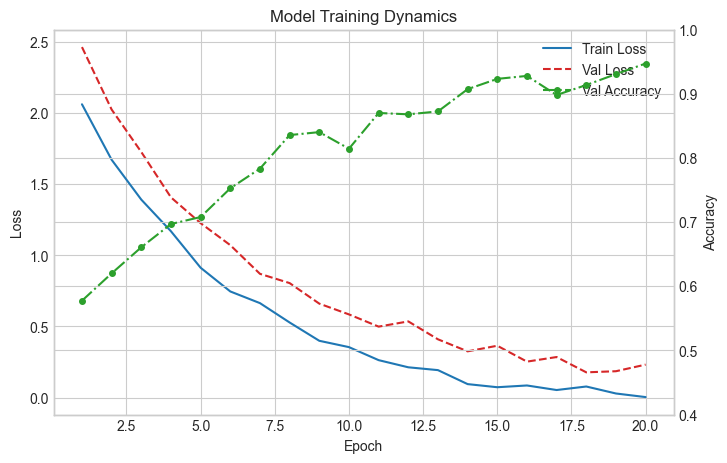

In [16]:
fig, ax1 = plt.subplots(figsize=(8,5))
line1, = ax1.plot(epochs,train_loss, color='tab:blue',label='Train Loss')
line2, = ax1.plot(epochs,val_loss, color='tab:red',linestyle='--',label='Val Loss')
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.set_title("Model Training Dynamics")
ax2 = ax1.twinx()
line3, = ax2.plot(epochs,val_accuracy,color='tab:green', linestyle='-.', marker='o', markersize=4, label='Val Accuracy')
ax2.set_ylabel('Accuracy')
ax2.set_ylim(0.4,1.0)

lines = [line1,line2,line3]
labels = [l.get_label() for l in lines]
ax1.legend(lines,labels,loc='upper right')


In [17]:
models = ['ResNet-50', 'EfficientNet-B0', 'Vision Transformer', 'MobileNet-V3', 'ConvNeXt']
latency_ms = [14.2, 8.5, 32.1, 4.8, 18.7]

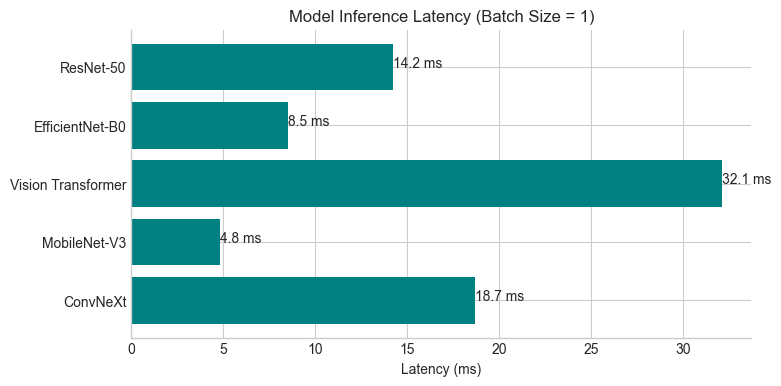

In [27]:
fig, ax = plt.subplots(figsize=(8,4))
rects = ax.barh(models,latency_ms,color="teal")
ax.invert_yaxis()
for i, rect in enumerate(rects):
    width = rect.get_width()
    y_pos = rect.get_y() + rect.get_height() / 2
    ax.annotate(text=f"{rect.get_width():.1f} ms", xy=(width, y_pos))
ax.set_title('Model Inference Latency (Batch Size = 1)')
ax.set_xlabel('Latency (ms)')
ax.spines[['top', 'right']].set_visible(False)